- <font size="3">(Fast/Discrete) Fourier transform (FFT/DFT)</font>
- <font size="3">Time signals with noise</font>
- <font size="3">Gravitational waves (GWs)</font>
- <font size="3">Fitting a gravitational wave</font>

### Preamble

In [2]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rcdefaults()

# plt.rc('font',**{'family':'serif','serif':['Times']})
# plt.rc('text', usetex=True)

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


%matplotlib inline

### Fourier transform

#### Mathematical definition

For a time dependent function (signal) $h(t)$, its Fourier transform $\tilde{h}(f)$ is a function of frequency $f$ and is defined as follows: 

$$
\tilde{h}(f) = \int\limits_{-\infty}^{+\infty}{h(t)e^{-2\pi i f t}\,{\rm d}t} \equiv \int\limits_{-\infty}^{+\infty}{h(t)\cos{(2\pi f t)}\,{\rm d}t} - i\int\limits_{-\infty}^{+\infty}{h(t)\sin{(2\pi f t)}\,{\rm d}t}\,,
$$
where $i$ is the imaginary unit, $i^2=-1$.

Inversely, given the Fourier transform $\tilde{h}(f)$, the signal can be recovered as
$$
h(t) = \int\limits_{-\infty}^{+\infty}{\tilde{h}(f)e^{2\pi i f t}\,{\rm d}f}\,.
$$

<u>Meaning</u>: Each time domain signal is represented as a sum of signals with different frequencies $f$ and *Fourier spectrum* $\tilde{h}(f)$. The latter is complex in general. Its magnitude squared as a function of the frequency is called *power spectrum*:

$$
\mbox{power spectrum:} \quad |\tilde{h}(f)|^2 \quad \mbox{(this one is real)} \,.
$$

#### Discrete Fourier transform (DFT)

DFT is an approximation to the exact integral above. In DFT, the integral is approximated as a *discrete* sum (a sum over a finite number of points).

#### Fast Fourier transform (FFT)

FFT is a numerical algorithm to compute DFT. The input of FFT is a signal given as a sequence of $N$ points. The output is the Fourier spectrum which is a sequence of complex numbers of the same length $N$, where each number is the value of $\tilde{h}(f)$ at some frequency.

The time performance of FFT grows $\propto N\log{N}$.

NumPy implements FFT routines in sublibrary `np.fft`. We will be using two of them: `np.fft.rfft(...)` and `np.fft.rfftfreq(...)`.

<u>EXAMPLE</u>: Consider a single sine wave. We will set its frequency $f_0=1$ Hz. We will also use $500$ points for a time interval of 5 seconds. This gives us 100 pts/s. For time signals, this number is called *sampling rate*. The word "sampling" is used here in a totally different sense than before.

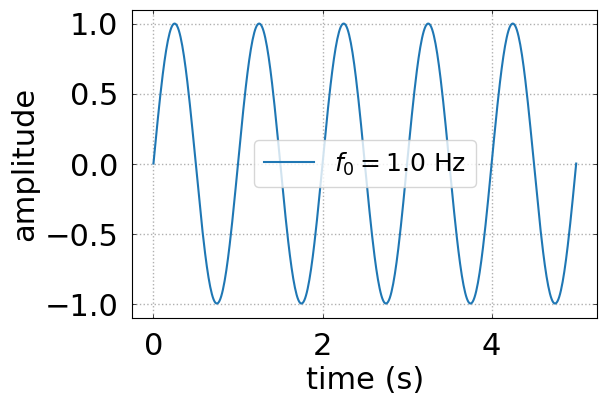

In [55]:
f0 = 1 # Hertz [Hz]

srate = 100 # a sampling rate of 100 pts/s.
T = 5  # a time interval of 5 seconds
t = np.linspace(0,T,int(srate*T))  # a signal of length T seconds and with a sampling srate
h = np.sin(2*np.pi*f0*t)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(t,h, label='$f_0=${:.1f} Hz'.format(f0))

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('time (s)')
ax.set_ylabel('amplitude')

ax.legend();

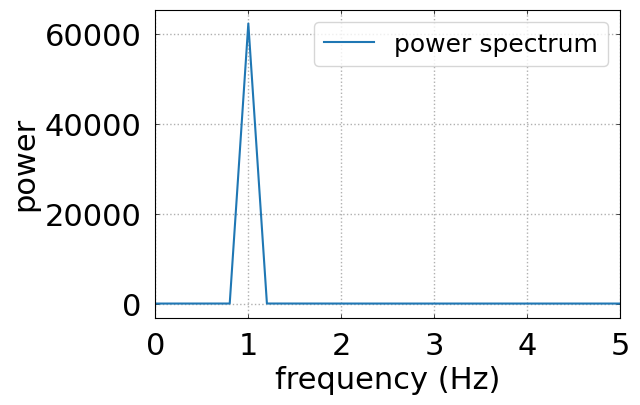

In [56]:
hf = np.fft.rfft(h)  # FFT
freqs = np.fft.rfftfreq(len(h), 1/srate)  # the second parameter is the inverse of the sampling rate
hPS = np.abs(hf)**2   # power spectrum for hf

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(freqs,hPS, label='power spectrum')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(0,5)


ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('power')

ax.legend();

<u>EXAMPLE</u>: Consider a sum of two sine waves: one with $f_1=1$ Hz and another with $f_2=4$ Hz.

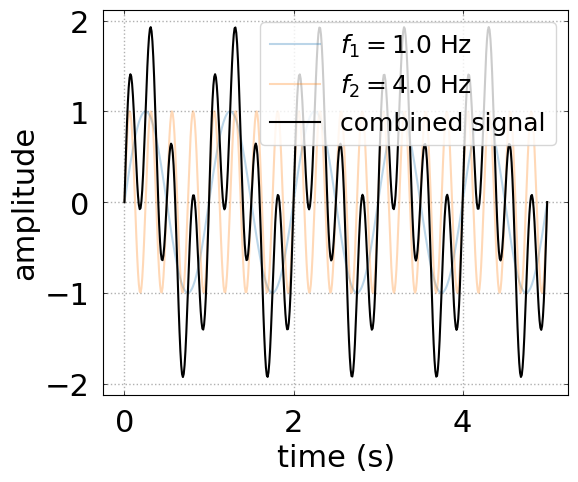

In [57]:
f1 = 1 # Hertz [Hz]
f2 = 4 # Hertz [Hz]

srate = 100 # a sampling rate of 100 pts/s.
T = 5  # a time interval of 5 seconds
t = np.linspace(0,T,srate*T)  # a signal of length T seconds and with a sampling srate
h1 = np.sin(2*np.pi*f1*t)
h2 = np.sin(2*np.pi*f2*t)
htot = h1+h2

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,5))

ax.plot(t,h1, label='$f_1=${:.1f} Hz'.format(f1), alpha=0.3)
ax.plot(t,h2, label='$f_2=${:.1f} Hz'.format(f2), alpha=0.3)
ax.plot(t, htot, label='combined signal', c='black')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('time (s)')
ax.set_ylabel('amplitude')

ax.legend();

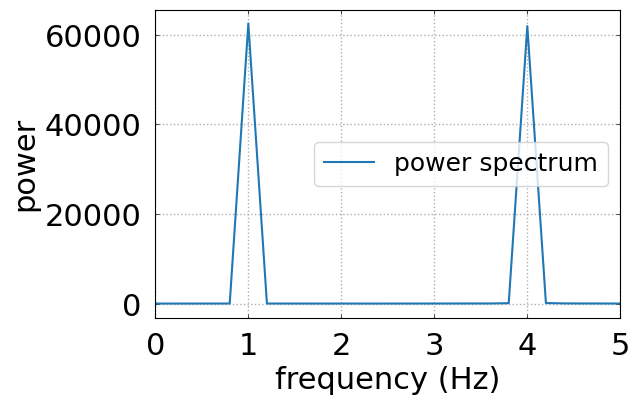

In [58]:
hf_tot = np.fft.rfft(htot)  # FFT
freqs = np.fft.rfftfreq(len(htot), 1./srate)  # the second parameter is the inverse of the sampling rate
hPS_tot = np.abs(hf_tot)**2   # power spectrum for hf

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(freqs,hPS_tot, label='power spectrum')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(0,5)


ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('power')

ax.legend();

#### A couple of numerical tweaks to make the result of an FFT look better

- FFT works better when the length of the time sequence is a power of 2. Therefore, before performing an FFT, the signal is *padded* with zeros: zeros are added until the length reaches a power of 2. The minimum is the nearest power, but the higher power is used, the smoother the Fourier spectrum will look.
- the exact FT requires an infinitely long signal while, in reality, we always have only a piece of the signal. This may lead to numerica artifacts in the Fourier spectrum. To avoid this, the signal is often multiplied by a *window function*, so that the signal is zero both at the very beginning and the end. This procedure is called *tapering* or *windowing*.

In [100]:
from scipy.signal.windows import tukey

def zero_pad(data, inc=0):  # inc defines whether we go for the nearest power of two or more
    """
    This function takes in a vector and zero pads it so it is a power of two.
    """
    N = len(data)
    pow_2 = np.ceil(np.log2(N)) + inc
    return np.pad(data,(0,int((2**pow_2)-N-1)),'constant')


def better_fft(signal, time, inc=0):
    """
    This function takes in a signal and the respective times, 
    multiplies it by a window function, pads the result with zeros,
    and perform an FFT. The output is two arrays: frequencies and the power spectrum.
    """
    
    dt = time[1]-time[0]
    N = len(signal)
    window = tukey(N, 0.05)
    signal_tapered = signal*window
    signal_padded = zero_pad(signal_tapered, inc)
    
    freqs = np.fft.rfftfreq(len(signal_padded), dt)
    hf = np.fft.rfft(signal_padded)
    
    return freqs, np.abs(hf)**2

<u>EXAMPLE</u>: Consider the same single sine wave as above but given on a different interval, so that the sine does not vanish at the end of the interval. Let us look at the FFT only with padding.

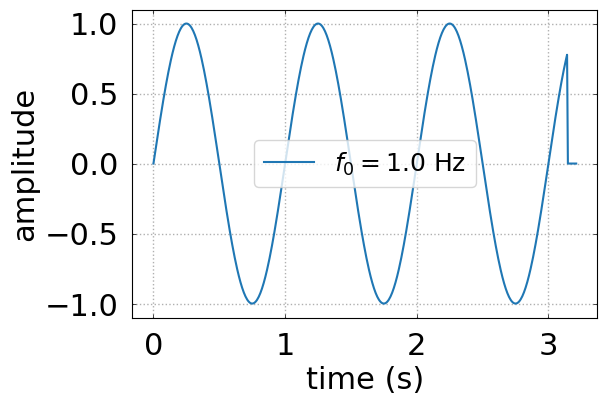

In [101]:
f0 = 1 # Hertz [Hz]

T = np.pi  # a time interval of 5 seconds
nn = 500
t = np.linspace(0,T,nn)  # a signal of length T seconds and given a number of points nn
dt = t[1] - t[0]
srate = nn/T
h = np.sin(2*np.pi*f0*t)
h_pad = zero_pad(h, inc=0)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(dt*np.arange(len(h_pad)),h_pad, label='$f_0=${:.1f} Hz'.format(f0))

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('time (s)')
ax.set_ylabel('amplitude')

ax.legend();

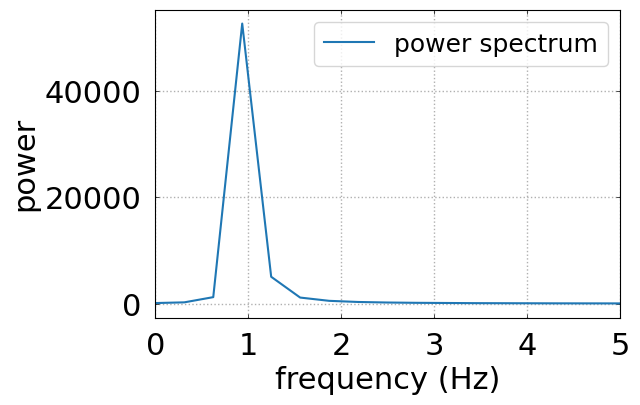

In [102]:
hf_pad = np.fft.rfft(h_pad)  # FFT
freqs = np.fft.rfftfreq(len(h_pad), 1./srate)  # the second parameter is the inverse of the sampling rate
hPS_pad = np.abs(hf_pad)**2   # power spectrum for hf

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(freqs,hPS_pad, label='power spectrum')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(0,5)


ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('power')

ax.legend();

<u>EXERCISE</u>

1. Experiment with the padding for the signal above. What happens to the plot of the power spectrum when higher powers of 2 are used?
2. Use a padding high enough so that the power spectrum looks smooth. Then compare the result to the output of the function `better_fft(..)` with the same value of `inc`. This function does tapering in addition to the padding. What happens to the power spectrum when the tapering is used?

### Power spectra for noise

#### White noise

The white-noise signal is a sequence of Gaussian amplitudes.

P.S. We can turn a sequence of Gaussian samples into a time sequence if we assign a moment of time to each sample. This assignment is arbitrary (depends on specific application), so we will not care about the exact time progression. We will use just a sample's number as a moment of time.

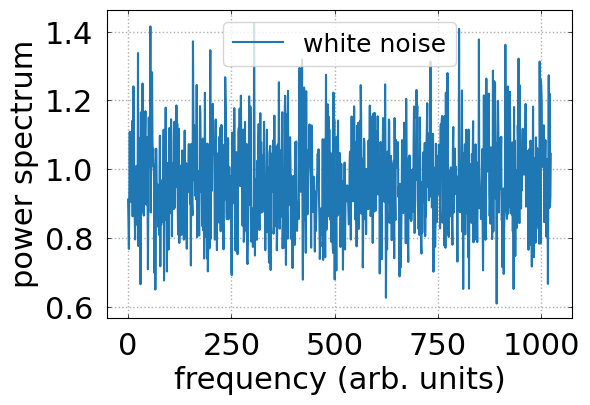

In [151]:
sigma = 1.

signal_len = 100000

white_noise = sigma*np.random.randn(signal_len)
_,wn_spectrum = better_fft(white_noise, np.arange(signal_len), inc=4)

averaging_len = 2**10
averaged_wn_spectrum = np.mean(wn_spectrum.reshape(-1, averaging_len), axis=1)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(averaged_wn_spectrum/signal_len, label='white noise')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('frequency (arb. units)')
ax.set_ylabel('power spectrum')

ax.legend();

#### Random walk

For random walk, we add the steps. It is a cumulative sum of the white noise.

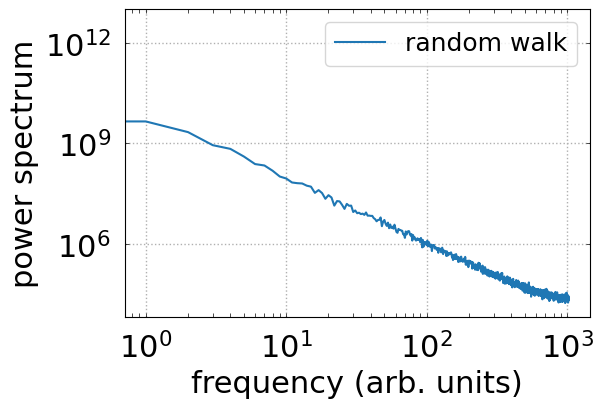

In [150]:
random_walk = np.cumsum(white_noise)

_,rw_spectrum = better_fft(random_walk, np.arange(signal_len), inc=4)

averaged_rw_spectrum = np.mean(rw_spectrum.reshape(-1, averaging_len), axis=1)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.loglog(averaged_rw_spectrum, label='random walk')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('frequency (arb. units)')
ax.set_ylabel('power spectrum')

ax.legend();

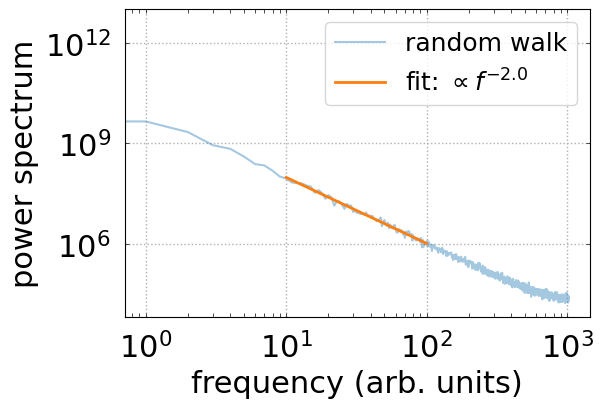

In [159]:
from scipy.optimize import curve_fit

def power_law(log_x, k,b):
    return k*log_x + b

x_vals = np.log10(np.linspace(10, 100, 91))

pars,_ = curve_fit(power_law, x_vals, np.log10(averaged_rw_spectrum[10:101]))

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.loglog(averaged_rw_spectrum, label='random walk', alpha=0.4)
ax.loglog(10**x_vals, 10**power_law(x_vals, *pars), label='fit: $\propto f^{{{:.1f}}}$'.format(pars[0]), lw=2)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('frequency (arb. units)')
ax.set_ylabel('power spectrum')

ax.legend();